In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/poojag718/rainfall-timeseries-data/Rainfall_data.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/poojag718/rainfall-timeseries-data/Rainfall_data.csv')

In [3]:
df.head(5)

,Year,Month,Day,Specific Humidity,Relative Humidity,Temperature,Precipitation
0,2000,1,1,8.06,48.25,23.93,0.00
1,2000,2,1,8.73,50.81,25.83,0.11
2,2000,3,1,8.48,42.88,26.68,0.01
3,2000,4,1,13.79,55.69,22.49,0.02
4,2000,5,1,17.40,70.88,19.07,271.14


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               252 non-null    int64  
 1   Month              252 non-null    int64  
 2   Day                252 non-null    int64  
 3   Specific Humidity  252 non-null    float64
 4   Relative Humidity  252 non-null    float64
 5   Temperature        252 non-null    float64
 6   Precipitation      252 non-null    float64
dtypes: float64(4), int64(3)
memory usage: 13.9 KB


In [5]:
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df = df.sort_values('Date').set_index('Date')

print(df.index.min(), df.index.max())
print(df.index.to_series().diff().value_counts().head())   # 1 day? ~30 days?
print(df.index.duplicated().sum())                         # should be 0
print(df.describe())

2000-01-01 00:00:00 2020-12-01 00:00:00
Date
31 days    146
30 days     84
28 days     15
29 days      6
Name: count, dtype: int64
0
              Year       Month    Day  Specific Humidity  Relative Humidity  \
count   252.000000  252.000000  252.0         252.000000         252.000000   
mean   2010.000000    6.500000    1.0          14.416746          67.259524   
std       6.067351    3.458922    0.0           4.382599          17.307101   
min    2000.000000    1.000000    1.0           5.740000          34.690000   
25%    2005.000000    3.750000    1.0          10.010000          51.845000   
50%    2010.000000    6.500000    1.0          15.200000          66.655000   
75%    2015.000000    9.250000    1.0          18.875000          84.610000   
max    2020.000000   12.000000    1.0          20.570000          92.310000   

       Temperature  Precipitation  
count   252.000000     252.000000  
mean     16.317262     206.798929  
std       6.584842     318.093091  
min       4

In [6]:
print(df.groupby(df.index.month)[['Temperature', 'Precipitation']].mean())

      Temperature  Precipitation
Date                            
1       22.948095       0.418095
2       24.500476       2.663333
3       24.458571       3.954286
4       21.600952       2.526667
5       17.209048      34.043333
6       11.890952     530.559048
7        6.090476     833.183810
8        6.137143     591.337143
9        9.796667     360.175238
10      14.971905     101.537143
11      16.618095      16.314762
12      19.584762       4.874286


      Temperature  Precipitation
Date                            
1            22.9            0.4
2            24.5            2.7
3            24.5            4.0
4            21.6            2.5
5            17.2           34.0
6            11.9          530.6
7             6.1          833.2
8             6.1          591.3
9             9.8          360.2
10           15.0          101.5
11           16.6           16.3
12           19.6            4.9


array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

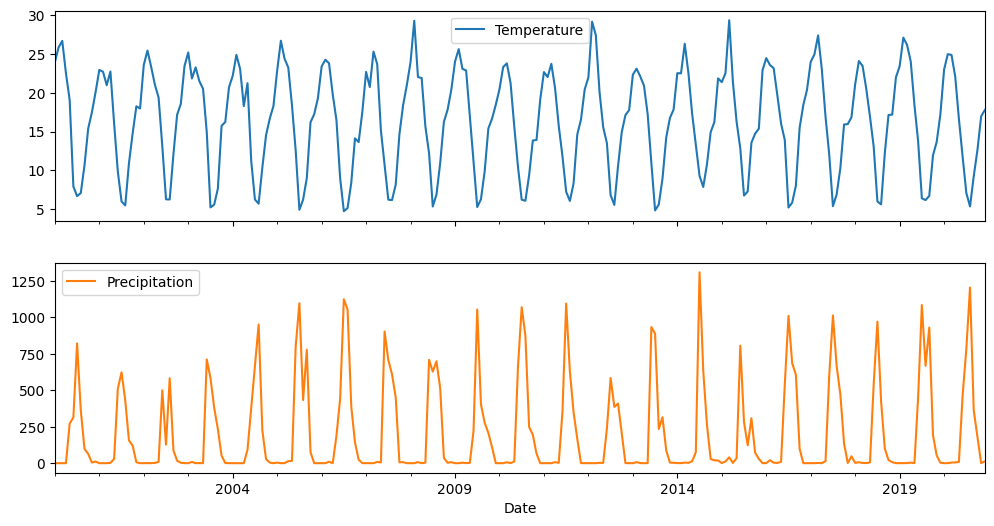

In [7]:
df = df.asfreq('MS')    # explicit monthly frequency
print(df.groupby(df.index.month)[['Temperature', 'Precipitation']].mean().round(1))
df[['Temperature', 'Precipitation']].plot(subplots=True, figsize=(12, 6))

In [8]:
from sklearn.metrics import mean_absolute_error

y = df['Temperature']
n_test = 36
train, test = y[:-n_test], y[-n_test:]

# Seasonal naive: same month last year
snaive = y.shift(12)[-n_test:]

# Climatology: average of each calendar month in the training years
clim_map = train.groupby(train.index.month).mean()
clim = pd.Series(test.index.month.map(clim_map), index=test.index)

print("Seasonal naive MAE:", mean_absolute_error(test, snaive))
print("Climatology MAE:   ", mean_absolute_error(test, clim))

Seasonal naive MAE: 2.0675000000000003
Climatology MAE:    1.27658950617284


In [9]:
feat = pd.DataFrame({'y': y})
for lag in [1, 2, 3, 12]:
    feat[f'lag_{lag}'] = feat['y'].shift(lag)
feat['month'] = feat.index.month
feat['year'] = feat.index.year
feat = feat.dropna()

X, t = feat.drop(columns='y'), feat['y']
from lightgbm import LGBMRegressor
m = LGBMRegressor(n_estimators=200, learning_rate=0.05, min_child_samples=10, verbose=-1)
m.fit(X[:-n_test], t[:-n_test])
print("LightGBM MAE:", mean_absolute_error(t[-n_test:], m.predict(X[-n_test:])))

LightGBM MAE: 1.6129827916700497


In [10]:
clim_map = train.groupby(train.index.month).mean()
clim_all = pd.Series(y.index.month.map(clim_map), index=y.index)
anom = y - clim_all

feat = pd.DataFrame({'anom': anom})
for lag in [1, 2, 3, 12]:
    feat[f'lag_{lag}'] = feat['anom'].shift(lag)
feat['month'] = feat.index.month          # no 'year' feature
feat = feat.dropna()

X, t = feat.drop(columns='anom'), feat['anom']
m = LGBMRegressor(n_estimators=100, learning_rate=0.03, min_child_samples=15, verbose=-1)
m.fit(X[:-n_test], t[:-n_test])

pred = m.predict(X[-n_test:]) + clim_all[feat.index][-n_test:].values
print("Anomaly model MAE:", mean_absolute_error(y[feat.index][-n_test:], pred))

Anomaly model MAE: 1.4156664762846067


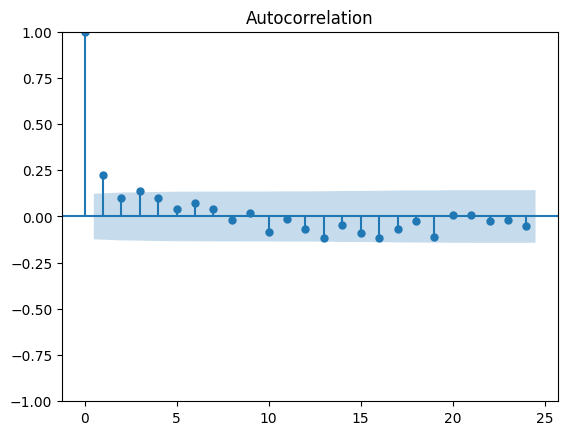

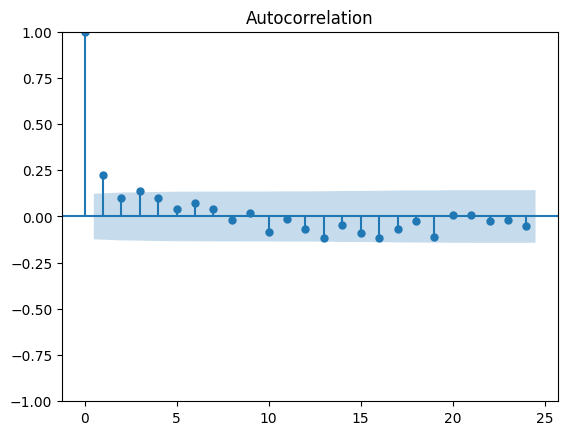

In [11]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(anom.dropna(), lags=24)

In [12]:
from sklearn.linear_model import Ridge

feat = pd.DataFrame({'anom': anom})
feat['lag_1'] = feat['anom'].shift(1)
feat = feat.dropna()

X, t = feat[['lag_1']], feat['anom']
r = Ridge(alpha=1.0).fit(X[:-n_test], t[:-n_test])

pred = r.predict(X[-n_test:]) + clim_all[feat.index][-n_test:].values
print("AR(1) anomaly MAE:", mean_absolute_error(y[feat.index][-n_test:], pred))
print("coef:", r.coef_)    # expect about 0.2

AR(1) anomaly MAE: 1.1596287074318807
coef: [0.15737194]


In [13]:
last_anom = anom.iloc[-1]
coef = r.coef_[0]
future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq='MS')

fc = []
a = last_anom
for d in future_idx:
    a = coef * a                               # anomaly decays each step
    fc.append(clim_map[d.month] + a)

forecast = pd.Series(fc, index=future_idx)

In [14]:
print(y['2000':'2009'].mean(), y['2010':'2020'].mean())

16.369666666666667 16.26962121212121


In [15]:
errs_ar, errs_clim = [], []
start = len(y) - n_test

for i in range(start, len(y)):
    tr = y.iloc[:i]                                   # data up to month i-1
    cm = tr.groupby(tr.index.month).mean()            # climatology from training only
    an = tr - tr.index.month.map(cm).values
    X_r = an.shift(1).dropna().values.reshape(-1, 1)
    y_r = an.iloc[1:].values
    mdl = Ridge(alpha=1.0).fit(X_r, y_r)

    month = y.index[i].month
    pred_ar = cm[month] + mdl.predict([[an.iloc[-1]]])[0]
    errs_ar.append(abs(y.iloc[i] - pred_ar))
    errs_clim.append(abs(y.iloc[i] - cm[month]))

print("Rolling AR(1) MAE:   ", np.mean(errs_ar))
print("Rolling climatology: ", np.mean(errs_clim))

Rolling AR(1) MAE:    1.157447330804298
Rolling climatology:  1.2872632391163097
